# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:

<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
#from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

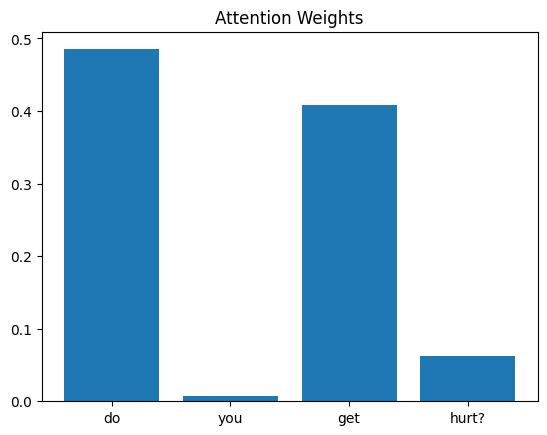

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question: do you get hurt?
Highest attention word: do


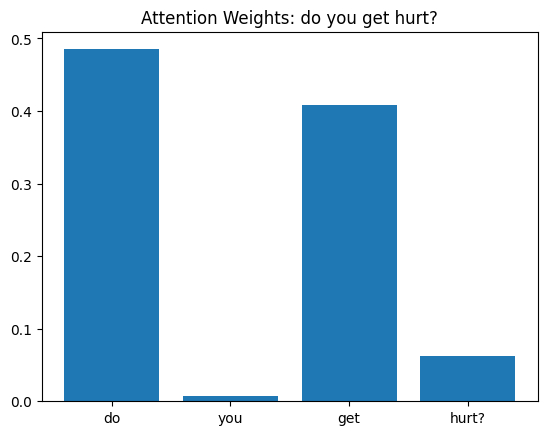

Question: who programmed you?
Highest attention word: programmed


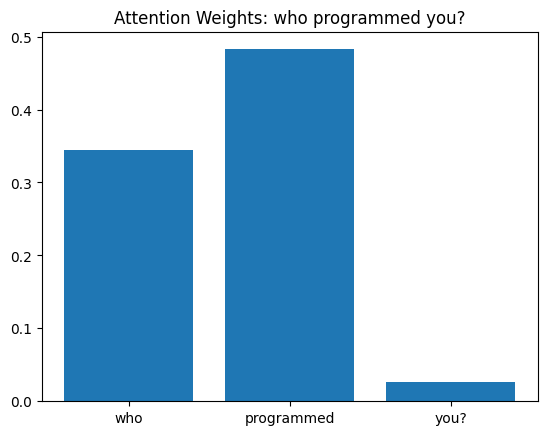

Question: do you ever eat pizza?
Highest attention word: eat


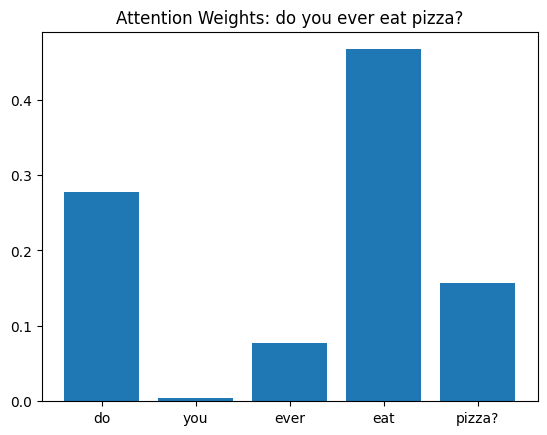

In [7]:
# Task 1: visualize attention weights for three different questions
indices = [0, 42, 100]

for i in indices:
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    w = weights[0, :len(words)].tolist()
    print("Question:", question)
    print("Highest attention word:", words[w.index(max(w))])

    plt.bar(words, w)
    plt.title("Attention Weights: " + question)
    plt.show()

**Answer (Task 1):**

- *"do you get hurt?"* → highest attention: **do** (with **get** close behind)
- *"who programmed you?"* → highest attention: **programmed**
- *"do you ever eat pizza?"* → highest attention: **eat**

Partly yes. In "who programmed you?" and "do you ever eat pizza?" the model focused on the key words (**programmed**, **eat**) that carry the meaning of the question and decide the answer (who created me / I don't need to eat). In "do you get hurt?", however, the highest weight went to **do**, a common word that is not important for the meaning, while the important word **hurt** got only a small weight. This shows that attention often highlights meaningful words, but because the model is small and trained for only 50 epochs, it sometimes gives high weight to frequent words instead of the most informative ones.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question: what's your age?
Highest attention word: age?


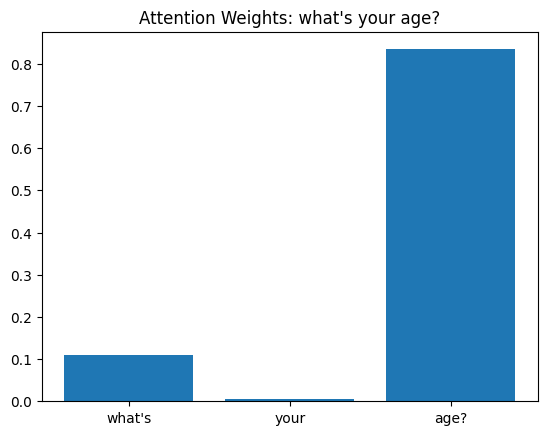

Question: how old are you?
Highest attention word: are


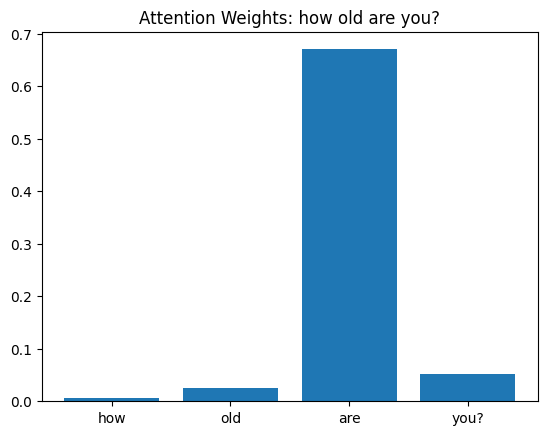

In [8]:
# Task 2: compare attention for two similar questions
indices = [20, 24]   # "what's your age?" and "how old are you?"

for i in indices:
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    w = weights[0, :len(words)].tolist()
    print("Question:", question)
    print("Highest attention word:", words[w.index(max(w))])

    plt.bar(words, w)
    plt.title("Attention Weights: " + question)
    plt.show()

**Answer (Task 2):**

Selected questions (same answer group: "Age doesn't really apply to me."):
- *"what's your age?"* → highest attention: **age?**
- *"how old are you?"* → highest attention: **are**

The model focused on different words. In the first question it focused on **age**, which is the key word, but in the second question it focused on **are** instead of the key word **old**. This suggests that attention does not work on meaning directly; it learns weights from the specific words and patterns seen during training. Questions with similar meaning but different wording can therefore receive different attention, and the weights depend on the training data and how well the model has learned, so attention weights do not always match what a human considers important.